In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14

cache = Path("../data/processed/retail_raw.pkl")

if cache.exists():
    df = pd.read_pickle(cache)
    print("Loaded from cache (fast)")
else:
    raw_path = next(Path("../data/raw").glob("*.xlsx"))
    print("Reading Excel (slow, 1-3 min):", raw_path)
    xls = pd.ExcelFile(raw_path)
    df = pd.concat(
        [pd.read_excel(raw_path, sheet_name=s) for s in xls.sheet_names],
        ignore_index=True,
    )
    df = df.rename(columns={
        "Invoice": "invoice",
        "StockCode": "stock_code",
        "Description": "description",
        "Quantity": "quantity",
        "InvoiceDate": "invoice_date",
        "Price": "price",
        "Customer ID": "customer_id",
        "Country": "country",
    })
    df["invoice_date"] = pd.to_datetime(df["invoice_date"], errors="coerce")
    df.to_pickle(cache)
    print("Saved cache for next time")

# Derived columns (always recomputed)
df["revenue"] = df["quantity"] * df["price"]
df["is_cancellation"] = df["invoice"].astype(str).str.startswith("C")

print(f"Shape: {df.shape}")
print(f"Date range: {df['invoice_date'].min()} -> {df['invoice_date'].max()}")
df.head()

Loaded from cache (fast)
Shape: (1067371, 10)
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,revenue,is_cancellation
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,False


In [2]:
print("=" * 50)
print("CELL 2: UNIQUE COUNTS")
print("=" * 50)
print(f"Unique customers: {df['customer_id'].nunique():,}")
print(f"Unique invoices:  {df['invoice'].nunique():,}")
print(f"Unique products:  {df['stock_code'].nunique():,}")
print(f"Unique countries: {df['country'].nunique()}")

print("\n" + "=" * 50)
print("CELL 3: MISSING VALUES")
print("=" * 50)
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}))

print("\n" + "=" * 50)
print("CELL 4: NEGATIVE QUANTITIES AND CANCELLATIONS")
print("=" * 50)
neg_qty = (df["quantity"] < 0).sum()
zero_qty = (df["quantity"] == 0).sum()
print(f"Negative quantity rows: {neg_qty:,} ({neg_qty/len(df)*100:.2f}%)")
print(f"Zero quantity rows:     {zero_qty:,}")
print(f"Cancellation invoices (start with C): {df['is_cancellation'].sum():,}")
print("\nCross-tab (rows: quantity<0, columns: is_cancellation):")
print(pd.crosstab(df["quantity"] < 0, df["is_cancellation"],
                  rownames=["quantity<0"], colnames=["is_cancellation"]))

anomalies = df[(df["quantity"] < 0) & (~df["is_cancellation"])]
print(f"\nNon-cancellation negatives: {len(anomalies):,}")
print(f"Of those, with a customer_id: {anomalies['customer_id'].notna().sum():,}")

print("\n" + "=" * 50)
print("CELL 5: ZERO AND NEGATIVE PRICES")
print("=" * 50)
print(f"Zero-price rows:     {(df['price'] == 0).sum():,}")
print(f"Negative-price rows: {(df['price'] < 0).sum():,}")
print(f"Zero-price rows WITH a customer_id: {((df['price'] == 0) & df['customer_id'].notna()).sum():,}")

print("\n" + "=" * 50)
print("CELL 6: DUPLICATES")
print("=" * 50)
full_dupes = df.duplicated().sum()
print(f"Fully duplicate rows: {full_dupes:,} ({full_dupes/len(df)*100:.2f}%)")
near = df.duplicated(subset=["invoice", "stock_code", "quantity", "price"]).sum()
print(f"Same invoice+stock+qty+price: {near:,}")

CELL 2: UNIQUE COUNTS
Unique customers: 5,942
Unique invoices:  53,628
Unique products:  5,305
Unique countries: 43

CELL 3: MISSING VALUES
                 missing_count  missing_pct
customer_id             243007        22.77
description               4382         0.41
stock_code                   0         0.00
invoice                      0         0.00
invoice_date                 0         0.00
quantity                     0         0.00
price                        0         0.00
country                      0         0.00
revenue                      0         0.00
is_cancellation              0         0.00

CELL 4: NEGATIVE QUANTITIES AND CANCELLATIONS
Negative quantity rows: 22,950 (2.15%)
Zero quantity rows:     0
Cancellation invoices (start with C): 19,494

Cross-tab (rows: quantity<0, columns: is_cancellation):
is_cancellation    False  True 
quantity<0                     
False            1044420      1
True                3457  19493

Non-cancellation negatives: 3,457

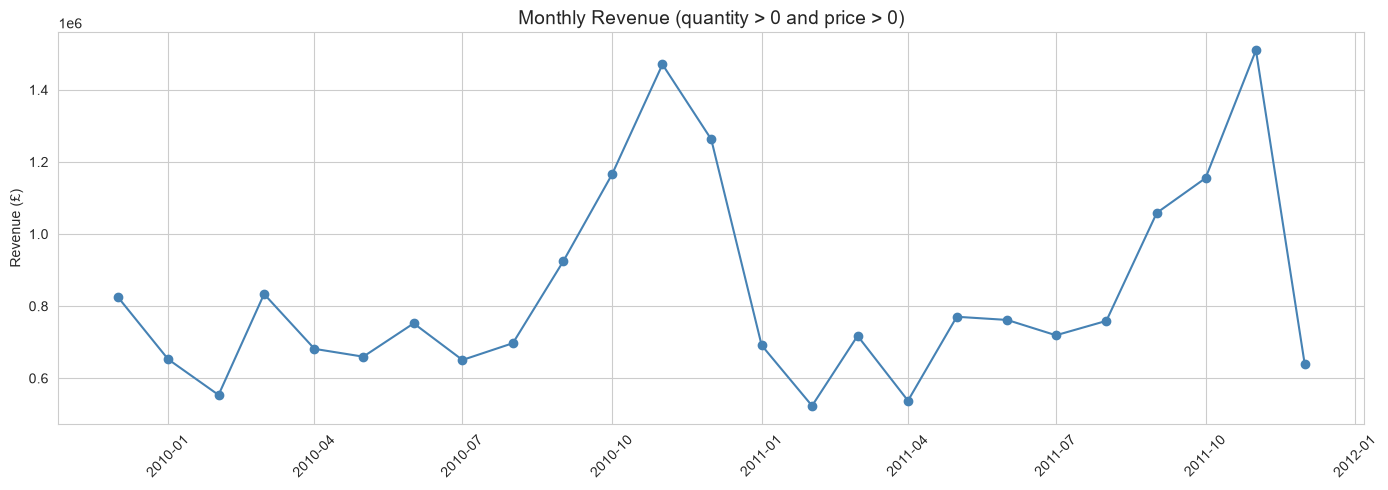

              revenue  orders
month                        
2009-12-01   825686.0    1682
2010-01-01   652709.0    1105
2010-02-01   553713.0    1202
2010-03-01   833570.0    1681
2010-04-01   681529.0    1462
2010-05-01   659859.0    1500
2010-06-01   752270.0    1645
2010-07-01   650713.0    1529
2010-08-01   697275.0    1425
2010-09-01   924333.0    1839
2010-10-01  1165484.0    2301
2010-11-01  1470272.0    2747
2010-12-01  1262599.0    1559
2011-01-01   691365.0    1086
2011-02-01   523632.0    1100
2011-03-01   717639.0    1454
2011-04-01   537809.0    1246
2011-05-01   770536.0    1681
2011-06-01   761740.0    1533
2011-07-01   719221.0    1475
2011-08-01   759138.0    1361
2011-09-01  1058590.0    1837
2011-10-01  1154979.0    2040
2011-11-01  1509496.0    2769
2011-12-01   638811.0     819


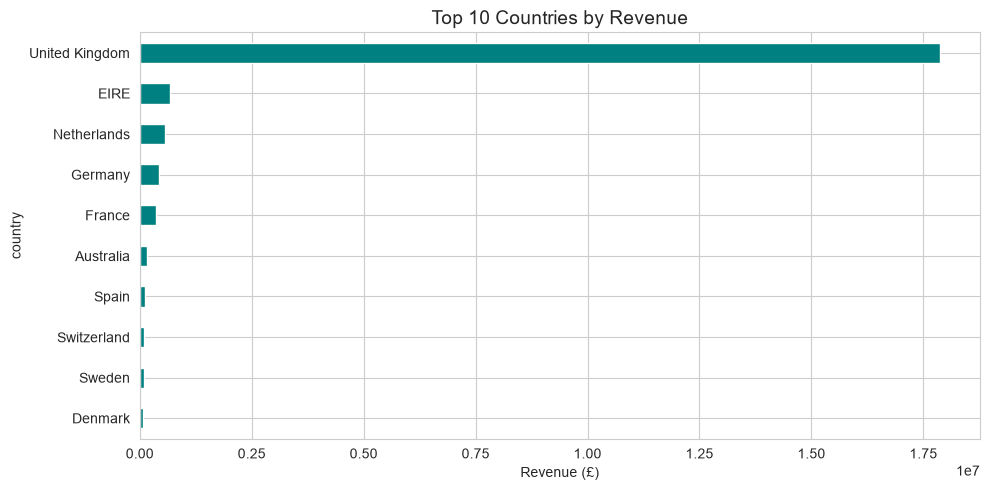


UK share of revenue: 85.2%


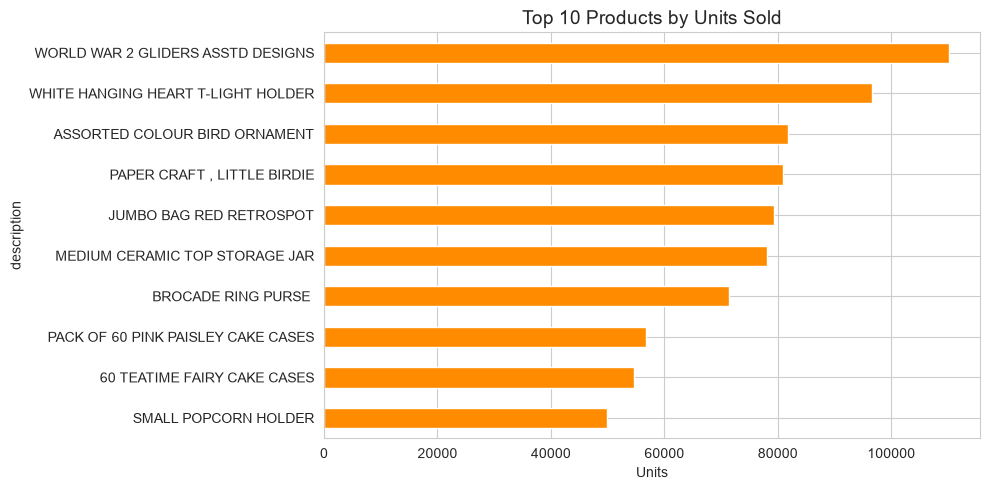


Rows whose stock code does not start with 5 digits: 4,794
stock_code
ADJUST          Adjustment by john on 26/01/2010 16
ADJUST2         Adjustment by Peter on Jun 25 2010 
AMAZONFEE                                AMAZON FEE
B                                   Adjust bad debt
BANK CHARGES                           Bank Charges
C2                                         CARRIAGE
D                                          Discount
DCGS0003                        BOXED GLASS ASHTRAY
DCGS0004                 HAYNES CAMPER SHOULDER BAG
DCGS0037                         KEY-RING CORKSCREW
DCGS0041           HAYNES MINI-COOPER PLAYING CARDS
DCGS0044                    HANDZ-OFF CAR FRESHENER
DCGS0058                           MISO PRETTY  GUM
DCGS0062                    ROAD-RAGE CAR FRESHENER
DCGS0066N                   NAVY CUDDLES DOG HOODIE
Name: description, dtype: object


In [3]:
# Rows with positive quantity and price (used for revenue views)
pos = df[(df["quantity"] > 0) & (df["price"] > 0)].copy()

# ---- 1. Monthly revenue ----
pos["month"] = pos["invoice_date"].dt.to_period("M").dt.to_timestamp()
monthly = pos.groupby("month").agg(
    revenue=("revenue", "sum"),
    orders=("invoice", "nunique"),
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly.index, monthly["revenue"], marker="o", color="steelblue")
ax.set_title("Monthly Revenue (quantity > 0 and price > 0)")
ax.set_ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(monthly.round(0))

# ---- 2. Top 10 countries ----
by_country = pos.groupby("country")["revenue"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
by_country.head(10).plot(kind="barh", ax=ax, color="teal")
ax.set_title("Top 10 Countries by Revenue")
ax.set_xlabel("Revenue (£)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print(f"\nUK share of revenue: {by_country['United Kingdom'] / by_country.sum() * 100:.1f}%")

# ---- 3. Top 10 products ----
top_products = (
    pos.groupby("description")["quantity"].sum().sort_values(ascending=False).head(10)
)
fig, ax = plt.subplots(figsize=(10, 5))
top_products.plot(kind="barh", ax=ax, color="darkorange")
ax.set_title("Top 10 Products by Units Sold")
ax.set_xlabel("Units")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# ---- 4. Stock codes that are not normal products ----
codes = pos["stock_code"].astype(str)
non_product = pos[~codes.str.match(r"^\d{5}")]
print(f"\nRows whose stock code does not start with 5 digits: {len(non_product):,}")
print(non_product.groupby("stock_code")["description"].first().head(15))

Clean rows: 805,549 of 1,067,371 (75.5%)
Customers with at least one clean purchase: 5,878

Orders per customer:
count    5878.0
mean        6.3
std        13.0
min         1.0
25%         1.0
50%         3.0
75%         7.0
90%        13.0
95%        21.0
99%        46.0
max       398.0
Name: orders, dtype: float64

Revenue per customer (£):
count      5878.0
mean       3019.0
std       14738.0
min           3.0
25%         349.0
50%         899.0
75%        2307.0
90%        5595.0
95%        9535.0
99%       29730.0
max      608822.0
Name: revenue, dtype: float64


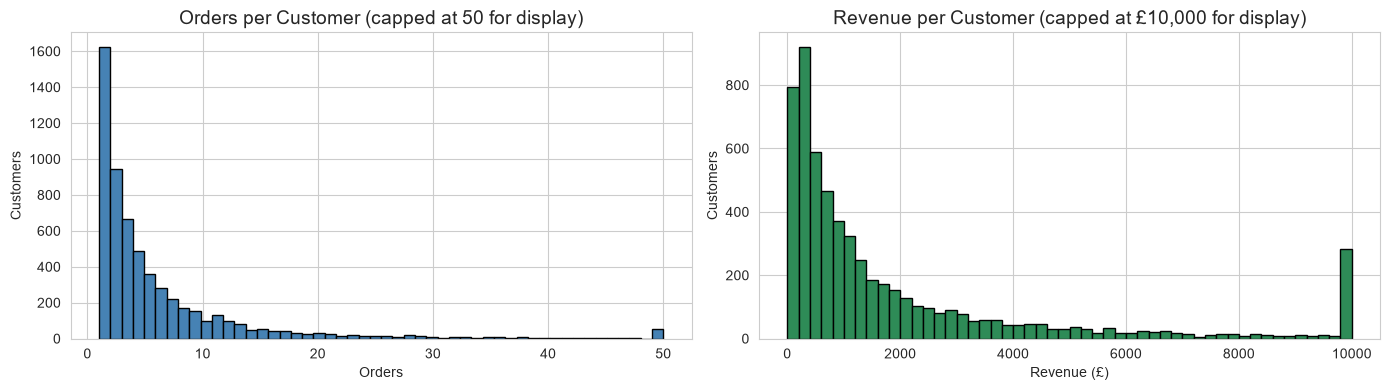

In [4]:
clean = df[
    (df["quantity"] > 0)
    & (df["price"] > 0)
    & (df["customer_id"].notna())
    & (~df["is_cancellation"])
].copy()

print(f"Clean rows: {len(clean):,} of {len(df):,} ({len(clean)/len(df)*100:.1f}%)")
print(f"Customers with at least one clean purchase: {clean['customer_id'].nunique():,}")

customer_stats = clean.groupby("customer_id").agg(
    orders=("invoice", "nunique"),
    revenue=("revenue", "sum"),
)

print("\nOrders per customer:")
print(customer_stats["orders"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1))
print("\nRevenue per customer (£):")
print(customer_stats["revenue"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(customer_stats["orders"].clip(upper=50), bins=50,
             color="steelblue", edgecolor="black")
axes[0].set_title("Orders per Customer (capped at 50 for display)")
axes[0].set_xlabel("Orders")
axes[0].set_ylabel("Customers")

axes[1].hist(customer_stats["revenue"].clip(upper=10000), bins=50,
             color="seagreen", edgecolor="black")
axes[1].set_title("Revenue per Customer (capped at £10,000 for display)")
axes[1].set_xlabel("Revenue (£)")
axes[1].set_ylabel("Customers")
plt.tight_layout()
plt.show()

In [5]:
data_end = df["invoice_date"].max()
snapshots = {
    "S1": "2010-06-30",
    "S2": "2010-09-30",
    "S3": "2011-03-30",
    "S4": "2011-09-10",
}

rows = []
for name, cutoff_str in snapshots.items():
    cut = pd.Timestamp(cutoff_str) + pd.Timedelta(days=1)   # start of day after the cutoff
    obs_start = cut - pd.Timedelta(days=180)
    pred_end = cut + pd.Timedelta(days=90)

    assert pred_end <= data_end + pd.Timedelta(days=1), f"{name}: prediction window passes end of data"

    obs = clean[(clean["invoice_date"] >= obs_start) & (clean["invoice_date"] < cut)]
    pred = clean[(clean["invoice_date"] >= cut) & (clean["invoice_date"] < pred_end)]

    eligible = set(obs["customer_id"].unique())
    buyers = set(pred["customer_id"].unique())
    positives = eligible & buyers

    rows.append({
        "snapshot": name,
        "cutoff": cutoff_str,
        "obs_start": obs_start.date(),
        "pred_end": (pred_end - pd.Timedelta(days=1)).date(),
        "eligible": len(eligible),
        "positives": len(positives),
        "positive_rate_%": round(len(positives) / len(eligible) * 100, 1),
    })

pd.DataFrame(rows)

,snapshot,cutoff,obs_start,pred_end,eligible,positives,positive_rate_%
0,S1,2010-06-30,2010-01-02,2010-09-28,2757,1399,50.7
1,S2,2010-09-30,2010-04-04,2010-12-29,2910,1682,57.8
2,S3,2011-03-30,2010-10-02,2011-06-28,3291,1451,44.1
3,S4,2011-09-10,2011-03-15,2011-12-09,2784,1722,61.9


## Findings

### Data quality
- 243,007 rows (22.77%) have no Customer ID and are unusable for customer-level modelling.
- 4,382 rows (0.41%) have no Description.
- 22,950 negative-quantity rows: 19,493 are cancellation invoices; 3,457 are non-cancellation negatives, none with a Customer ID, so they never enter customer-level modelling.
- 6,202 zero-price rows (only 71 with a Customer ID) and 5 negative-price rows, removed by the price > 0 rule.
- 34,335 fully duplicate rows (3.22%). Kept for now: duplicates do not change a did-they-buy target. Revisit for revenue features.
- Clean rows (qty > 0, price > 0, has customer, not cancelled): ___ of 1,067,371 (___%).

### Business shape
- 5,942 customers, 53,628 invoices, 5,305 products, 43 countries.
- UK share of revenue: ___%.
- Peak revenue months: ___. Lowest: ___ (Dec 2011 is partial).
- Median orders per customer: ___; 99th percentile: ___.
- Median revenue per customer: £___; 99th percentile: £___.
- Non-product stock codes seen: ___ (___ rows).

### Class balance by snapshot
| Snapshot | Eligible | Positives | Positive rate |
|---|---|---|---|
| S1 | | | |
| S2 | | | |
| S3 | | | |
| S4 | | | |

### Implications
- Metric choice: ___ because ___.
- Seasonality: the test window (S4, Sep to Dec) ___ compared with validation (S3).